In [1]:
# Mount Google Drive and Set Paths
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Setup and load

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

base_dir = Path("/content/drive/MyDrive/gdsc-drug-response")
data_path = base_dir / "processed" / "fulvestrant_rnaseq_modelready_clean.csv"
df = pd.read_csv(data_path)

df.shape
df.head()

,model_id,drug_name,ln_ic50,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
0,SIDM01132,Fulvestrant,2.325255,5.18545,2.9833,0.0000,0.52325,0.0000,0.0213,0.0000,...,6.17065,0.31285,1.60475,3.10825,0.6801,0.0,2.58955,5.95435,3.47415,4.0301
1,SIDM00848,Fulvestrant,2.710606,4.86890,3.4476,0.0000,1.99640,0.1243,3.1890,0.0000,...,7.09150,1.68260,2.33060,5.18630,0.0841,0.0,3.09930,5.52420,3.60640,4.5211
2,SIDM00263,Fulvestrant,2.869553,5.03650,3.5558,0.0144,3.98550,0.2987,5.7968,0.0566,...,5.69660,2.94860,3.39230,6.59630,4.1787,0.0,4.68090,6.37780,4.57590,5.6946
3,SIDM00269,Fulvestrant,2.028349,4.54970,3.8001,0.0841,3.21570,0.0566,0.5753,0.0000,...,4.53920,2.82980,3.41280,6.78270,2.3190,0.0,4.21410,9.01050,4.93400,5.4561
4,SIDM00203,Fulvestrant,3.070346,4.22500,3.2095,0.0144,0.50590,0.0976,2.8156,0.0000,...,6.45100,2.49570,3.47640,5.30710,3.0321,0.0,4.47310,6.95290,4.35900,5.3366


In [3]:
# Define columns:

model_col    = "model_id"
drug_col     = "drug_name"
response_col = "ln_ic50"

non_feature_cols = [model_col, drug_col, response_col]
feature_cols = [c for c in df.columns if c not in non_feature_cols]

# Fill NaNs in features with the column mean
df_imputed = df.copy()
df_imputed[feature_cols] = df_imputed[feature_cols].fillna(df_imputed[feature_cols].mean())

# Optionally, confirm no NaNs remain
df_imputed[feature_cols].isna().any().sum()  # should be 0

# Compute variance of each gene feature
feature_var = df_imputed[feature_cols].var()

# Choose top N genes by variance (e.g., 2000; you can also try 1000 or 5000)
N = 2000
top_genes = feature_var.sort_values(ascending=False).head(N).index.tolist()

len(top_genes), top_genes[:10]

X = df_imputed[top_genes].values
y = df_imputed[response_col].values

X.shape, y.shape

((1636, 2000), (1636,))

In [4]:
#  Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

X_train.shape, X_test.shape

((1308, 2000), (328, 2000))

In [5]:
# Pipeline: StandardScaler + Ridge

ridge = make_pipeline(
    StandardScaler(with_mean=True, with_std=True),
    Ridge(alpha=1.0, random_state=42)
)

ridge.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('ridge', Ridge(random_state=42))])

 Evaluate with multiple metrics and plots

In [6]:
# Predictions:

y_train_pred = ridge.predict(X_train)
y_test_pred  = ridge.predict(X_test)

In [7]:
# Metrics (R², RMSE, MAE) to get different views of performance.

def regression_metrics(y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

r2_train, rmse_train, mae_train = regression_metrics(y_train, y_train_pred)
r2_test,  rmse_test,  mae_test  = regression_metrics(y_test, y_test_pred)

print("Train: R2={:.3f}, RMSE={:.3f}, MAE={:.3f}".format(r2_train, rmse_train, mae_train))
print("Test : R2={:.3f}, RMSE={:.3f}, MAE={:.3f}".format(r2_test,  rmse_test,  mae_test))

print("Ridge (top {} genes): Train R2={:.3f}, Test R2={:.3f}".format(N, r2_train, r2_test))

Train: R2=0.655, RMSE=0.742, MAE=0.554
Test : R2=-0.815, RMSE=1.635, MAE=1.397
Ridge (top 2000 genes): Train R2=0.655, Test R2=-0.815


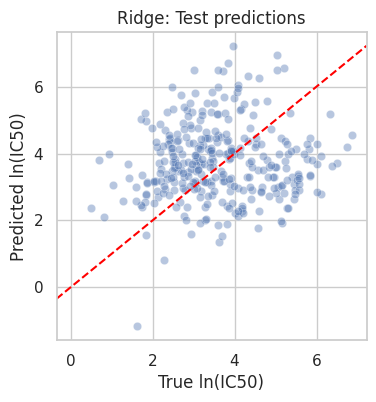

In [8]:
# Predicted vs true (test set):

plt.figure(figsize=(4,4))
sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.4)
plt.xlabel("True ln(IC50)")
plt.ylabel("Predicted ln(IC50)")
plt.axline((0,0), slope=1, color="red", linestyle="--")
plt.title("Ridge: Test predictions")
plt.show()

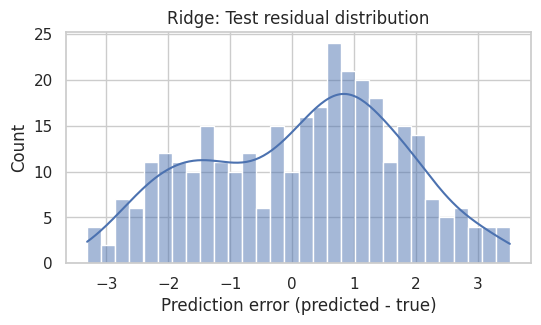

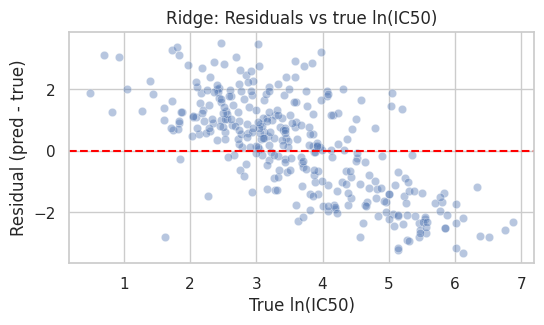

In [9]:
# Residuals (test set) to see error structure:

residuals = y_test_pred - y_test

plt.figure(figsize=(6,3))
sns.histplot(residuals, bins=30, kde=True)
plt.xlabel("Prediction error (predicted - true)")
plt.title("Ridge: Test residual distribution")
plt.show()

plt.figure(figsize=(6,3))
sns.scatterplot(x=y_test, y=residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("True ln(IC50)")
plt.ylabel("Residual (pred - true)")
plt.title("Ridge: Residuals vs true ln(IC50)")
plt.show()

Interpret Ridge coefficients

In [10]:
# Get the fitted Ridge model and map coefficients back to gene names:

# Grab the underlying Ridge model out of the pipeline
scaler, ridge_model = ridge.named_steps["standardscaler"], ridge.named_steps["ridge"]

coef = ridge_model.coef_  # shape: (n_features,)
len(coef), len(feature_cols)

(36438, 36438)

In [11]:
# Create a dataframe of gene coefficients:

coef_df = pd.DataFrame({
    "gene": feature_cols,
    "coef": coef
})

coef_df["abs_coef"] = coef_df["coef"].abs()
coef_df.sort_values("abs_coef", ascending=False).head(10)

,gene,coef,abs_coef
23857,PSMC1P12,-0.007544,0.007544
1372,ARF1P3,0.007469,0.007469
30329,SNORA16A,-0.007033,0.007033
25140,RN7SKP147,0.006373,0.006373
12194,IGKV1OR22-1,-0.006205,0.006205
14281,LINC00410,0.006196,0.006196
7019,DUXAP3,0.005960,0.005960
21216,OR7D1P,-0.005922,0.005922
21269,OR7E24,-0.005831,0.005831
15167,LINC01787,0.005711,0.005711


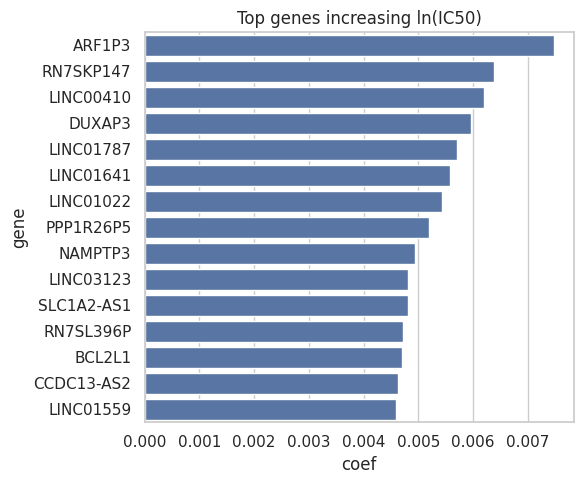

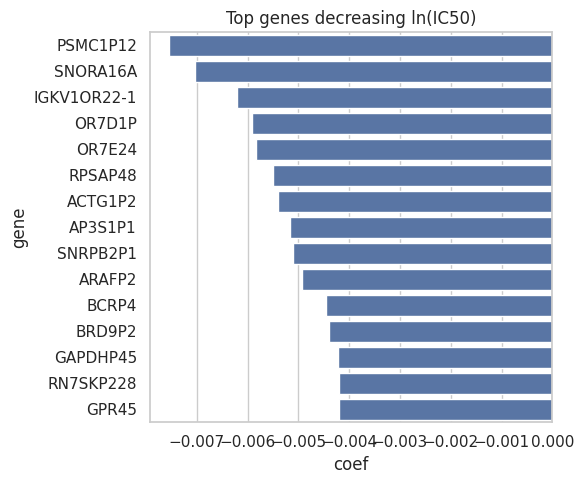

In [12]:
# Plot top positive/negative:

top_pos = coef_df.sort_values("coef", ascending=False).head(15)
top_neg = coef_df.sort_values("coef", ascending=True).head(15)

plt.figure(figsize=(6,5))
sns.barplot(data=top_pos, x="coef", y="gene")
plt.title("Top genes increasing ln(IC50)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,5))
sns.barplot(data=top_neg, x="coef", y="gene")
plt.title("Top genes decreasing ln(IC50)")
plt.tight_layout()
plt.show()

In [13]:
# (Optional) Try a couple of alpha values

alphas = [0.1, 1.0, 10.0, 100.0]
results = []

for a in alphas:
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=a, random_state=42)
    )
    model.fit(X_train, y_train)
    y_tr_pred = model.predict(X_train)
    y_te_pred = model.predict(X_test)
    r2_tr, rmse_tr, _ = regression_metrics(y_train, y_tr_pred)
    r2_te, rmse_te, _ = regression_metrics(y_test,  y_te_pred)
    results.append((a, r2_tr, rmse_tr, r2_te, rmse_te))

pd.DataFrame(results, columns=["alpha", "R2_train", "RMSE_train", "R2_test", "RMSE_test"])

,alpha,R2_train,RMSE_train,R2_test,RMSE_test
0,0.1,0.655456,0.742335,-0.726942,1.594595
1,1.0,0.655456,0.742335,-0.726854,1.594554
2,10.0,0.655456,0.742335,-0.725974,1.594147
3,100.0,0.655443,0.742348,-0.717272,1.590124
